Do not immediately answer my question. First identify what I'm actually trying to solve. Ask me the three most important questions that would help you give me a much better answer.

I'm going to share an idea with you. Your job isn't to agree with me. Find the 5 biggest weaknesses, challenge my assumptions, identify what I'm overlooking, and tell me what could make this fail.

I want to achieve [result]. Work backward from desired outcome. Identify the exact steps, skills tools, decisions, and milestones required to get there. Explain the most efficient path.

As a top 1% expert in [field]. Evaluate my current approach, identify what beginners misunderstand, explain what experienced professionals do differently, and show me to think at an advanced level.

Act as my expert advisor. Here is my situation: [context]. Here is what I want to achieve: [goal]. Identify my biggest leverage point.

# Problem 10.4: same five-step protocol

**Answer: N ≈ 2.56 × 10⁵ cycles** to grow the crack from a/W = 0.35 to 0.60. The program is in `ct_fatigue_crack_growth.py` and the plot of crack length versus cycles is in `ct_crack_growth.png`.

---

## Prompt 1: What you're actually solving, and the three key questions

**What you're solving.** This is Problem 10.1 with a **real specimen geometry**. In a compact specimen, K depends on a/W through a complicated polynomial, so the integral has **no closed-form solution**. The task is to integrate numerically and produce the full a-versus-N history, not just a final number. Being able to build that integration yourself is the skill being tested.

**The three questions I'd ask, and the answers I'm assuming:**
1. *What are the specimen dimensions?* A "1T" specimen is 1 inch thick, so B = 25.4 mm and W = 2B = 50.8 mm (Anderson Section 7.1.1).
2. *Which K solution?* The standard ASTM E399 compact-specimen expression from Section 7.1.1.
3. *Program or spreadsheet?* I wrote a Python program, and I explain the spreadsheet version too, since the logic is the same.

---

## Prompt 2: The five biggest weaknesses of the "obvious" approach

1. **Using ΔK = YΔσ√(πa).** Compact specimens are loaded in **force**, not remote stress. You must use the compact-specimen expression K = P/(B√W)·f(a/W). There is no Δσ in this problem.
2. **Using P_max instead of ΔP.** Crack growth is driven by ΔP = 18 − 5 = **13 kN**. P_max only matters for checking whether the specimen fractures.
3. **Using steps that are too coarse.** da/dN increases about 10× over the range, so a crude rectangle-rule spreadsheet can be noticeably wrong. Use the trapezoid rule with small steps and check that the answer converges.
4. **Mixing units.** P in kN with B and W in mm gives K in nonsense units. Use MN and m so that K comes out in MPa√m, matching C.
5. **Never checking whether the material survives to a/W = 0.60.** K_max reaches about 43 MPa√m. If this were the steel from 10.2 (K_Ic = 25 MPa√m), the specimen would **fracture near a/W ≈ 0.44** and never reach 0.60. The problem doesn't specify the material, but an expert checks this.

---

## Prompt 3: Fully worked solution

### Work backward from the goal
Find N by summing dN = da / (C·ΔK³). That requires ΔK(a), which comes from ΔP, B, W and f(a/W). Since f has no simple integral, you integrate numerically.

### Step 1: Set up the inputs
- W = 0.0508 m and B = 0.0254 m
- ΔP = 0.013 MN, so R = 5/18 = 0.28
- a₀ = 0.35W = **17.78 mm** and a_f = 0.60W = **30.48 mm**

### Step 2: The K expression

$$\Delta K = \frac{\Delta P}{B\sqrt{W}}\, f\!\left(\tfrac{a}{W}\right), \qquad f(x) = \frac{(2+x)(0.886 + 4.64x - 13.32x^2 + 14.72x^3 - 5.6x^4)}{(1-x)^{3/2}}$$

The prefactor is ΔP/(B√W) = 0.013 / (0.0254 × 0.2254) = **2.271 MPa√m**.

### Step 3: Integrate numerically

$$N = \int_{a_0}^{a_f} \frac{da}{C\,[\Delta K(a)]^3}$$

**The algorithm, which works the same way in code or a spreadsheet:**
1. Divide the crack range into small steps Δa.
2. At each crack length, compute f(a/W), then ΔK, then da/dN = CΔK³.
3. Cycles for each step: ΔN = Δa / (average da/dN over the step).
4. Keep a running total of ΔN to get the a-versus-N history.

### Results

| a/W | a (mm) | f(a/W) | ΔK (MPa√m) | K_max (MPa√m) | da/dN (m/cycle) | N (cycles) |
|---|---|---|---|---|---|---|
| 0.35 | 17.78 | 6.39 | 14.5 | 20.1 | 2.1 × 10⁻⁸ | 0 |
| 0.40 | 20.32 | 7.28 | 16.5 | 22.9 | 3.1 × 10⁻⁸ | 100,200 |
| 0.45 | 22.86 | 8.34 | 18.9 | 26.2 | 4.7 × 10⁻⁸ | 167,600 |
| 0.50 | 25.40 | 9.66 | 21.9 | 30.4 | 7.2 × 10⁻⁸ | 211,800 |
| 0.55 | 27.94 | 11.36 | 25.8 | 35.7 | 1.2 × 10⁻⁷ | 239,600 |
| 0.60 | 30.48 | 13.65 | 31.0 | 42.9 | 2.0 × 10⁻⁷ | **256,300** |

### Verification
- Adaptive quadrature and a 2,000-step trapezoid rule agree exactly.
- A 25-step spreadsheet-style grid (steps of 0.01 in a/W) is only 0.05% high, so the answer has converged.

**Final answer: N ≈ 2.56 × 10⁵ cycles.** The plot shows the typical accelerating curve: slow early growth that turns sharply upward as a/W approaches 0.60.

---

## Prompt 4: Expert evaluation

**Beginners misunderstand:**
- **Why compact specimens exist.** They aren't a model of a real part. They're a **test specimen** designed to measure da/dN data. This problem is essentially simulating a da/dN test, which is the reverse of how such tests are run.
- **The geometry factor.** f(a/W) rises from 6.4 to 13.7 over this range because the remaining ligament shrinks and bending dominates. So ΔK more than doubles even though the load is constant.
- **Where the life goes.** **75%** of the cycles are spent in the first half of the crack-length range, the same pattern as Problems 10.1 and 10.2.

**What professionals do differently:**
- **Run the problem in reverse.** In an actual ASTM E647 test, a and N are measured by compliance or potential drop, and da/dN is then calculated from the data by fitting the slope of the a-versus-N curve (secant or incremental polynomial methods). Being able to compute it in both directions is what makes you competent with the test.
- **Check specimen validity.** E647 requires the uncracked ligament (W − a) to remain large compared with the plastic zone. At a/W = 0.60, W − a = 20 mm. That's fine for a high-strength steel but may be marginal for a low-yield aluminum.
- **Use load shedding near threshold.** Constant-amplitude loading like this captures Region II but can't measure ΔK_th. To get there, the load is reduced step by step as the crack grows (decreasing-K testing).
- **Check K_max against toughness at every step,** and stop the integration when it reaches K_c (as in 10.2). Good code makes that a stopping condition rather than relying on the user to remember.

**How to think at an advanced level:**
- **Separate the problem into modules.** Geometry gives K(a), the material law gives da/dN(ΔK), and the integration step is generic. Swapping any one of them (another specimen, the Walker equation, a different integrator) leaves the others untouched. That's how professional tools like NASGRO and AFGROW are structured.
- **Make the code check its own accuracy.** Compare two methods and two step sizes, as the program does. Never trust a single numerical answer.

---

## Prompt 5: Your biggest leverage point

**The leverage point is the numerical integration loop itself: a → ΔK(a) → da/dN → ΔN, summed.**

Problems 10.1 and 10.2 worked out neatly because ΔK ∝ √a. Real geometries almost never allow that. Once you can write this loop, you can solve **any** fatigue crack growth problem, whatever the geometry, the growth law or the load history:
- **New geometry?** Swap in a different f(a/W).
- **R effects (Problem 10.3)?** Replace CΔKᵐ with Walker or Forman.
- **Fracture limit (Problem 10.2)?** Add "stop when K_max ≥ K_c."
- **Variable loading?** Step through the load cycles instead of assuming constant amplitude.

**Milestone for full understanding:**
1. Rebuild this in a spreadsheet from scratch with columns a, a/W, f, ΔK, da/dN, ΔN and running N. Confirm you get about 256,000 cycles.
2. Add a stopping condition at K_max = 25 MPa√m, and find the a/W where the 10.2 steel would fracture (around 0.44).
3. Explain why halving the step size barely changes the answer here, but would matter much more near a/W → 1.

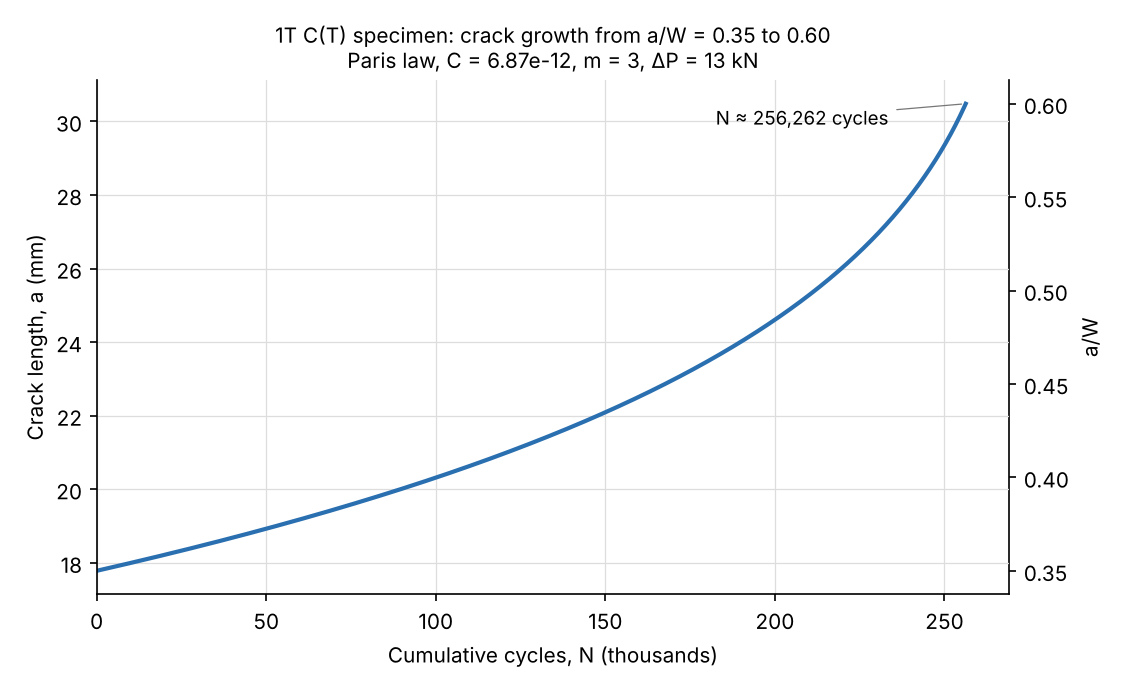